# Neural Networks More Hidden Neurons — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/neural-networks-more-hidden-neurons.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Neural Networks More Hidden Neurons</h1>


**Estimated time needed**: 25 minutes


## Learning Objectives
After completing this lab, you will be able to:
- Create complex Neural Network in PyTorch 


<h2>Table of Contents</h2>

<ol>
<li><a href="#Import-the-Libraries">Import the Libraries</a> 
</li>
<li><a href="#Visualize-the-Activations-and-Model-Predictions">Visualize the Activations and Model Predictions</a>     
</li>
<li><a href="#Get-the-Data">Get the Data</a>     
</li>
<li><a href="#Define-the-Neural-Network-and-Optimizer">Define the Neural Network and Optimizer</a>     
</li>
</ol>


## Import the Libraries


We'll need to import the following libraries for this lab.


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Matplotlib is building the font cache; this may take a moment.


## Visualize the Activations and Model Predictions


The following functions are used to visualize the activation distributions and the model predictions during training.


In [3]:
def get_hist(model, data_set):
    activations = model.activation(data_set.x)
    for i, activation in enumerate(activations):
        plt.hist(activation.numpy(), 4, density=True)
        plt.title('Activation layer ' + str(i + 1))
        plt.xlabel('Activation')
        plt.xlabel('Activation')
        plt.legend()
        plt.show()

In [4]:
def PlotStuff(X, Y, model=None, leg=False):
    plt.plot(X[Y == 0].numpy(), Y[Y == 0].numpy(), 'or', label='training points y=0 ')
    plt.plot(X[Y == 1].numpy(), Y[Y == 1].numpy(), 'ob', label='training points y=1 ')
    if model != None:
        plt.plot(X.numpy(), model(X).detach().numpy(), label='neral network ')
    plt.legend()
    plt.show()

## Get the Data


Define the class to get our dataset.


In [5]:
class Data(Dataset):

    def __init__(self):
        self.x = torch.linspace(-20, 20, 100).view(-1, 1)
        self.y = torch.zeros(self.x.shape[0])
        self.y[(self.x[:, 0] > -10) & (self.x[:, 0] < -5)] = 1
        self.y[(self.x[:, 0] > 5) & (self.x[:, 0] < 10)] = 1
        self.y = self.y.view(-1, 1)
        self.len = self.x.shape[0]

    def __getitem__(self, index):
        return (self.x[index], self.y[index])

    def __len__(self):
        return self.len

## Define the Neural Network and Optimizer


Define the class for creating the model:


In [6]:
class Net(nn.Module):

    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H, D_out)

    def forward(self, x):
        x = torch.sigmoid(self.linear1(x))
        x = torch.sigmoid(self.linear2(x))
        return x

Create a function to train the model that accumulates the loss for each iteration to compute the cost.


In [7]:
def train(data_set, model, criterion, train_loader, optimizer, epochs=2, plot_number=10):
    cost = []
    for epoch in itertools.islice(range(epochs), 2):
        total = 0
        for x, y in train_loader:
            optimizer.zero_grad()
            yhat = model(x)
            loss = criterion(yhat, y)
            loss.backward()
            optimizer.step()
            total += loss.item()
        if epoch % plot_number == 0:
            PlotStuff(data_set.x, data_set.y, model)
        cost.append(total)
    plt.figure()
    plt.plot(cost)
    plt.xlabel('epoch')
    plt.ylabel('cost')
    plt.show()
    return cost

In [8]:
data_set = Data()

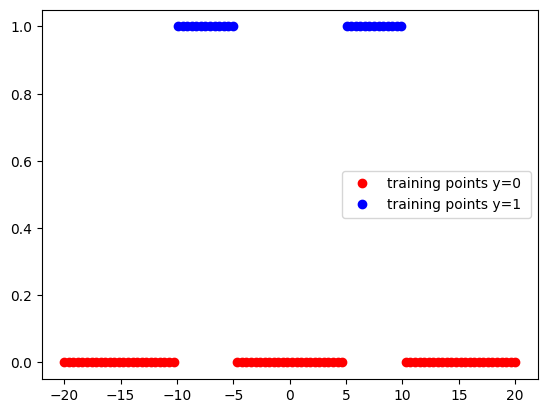

In [9]:
PlotStuff(data_set.x, data_set.y, leg=False)

Create a model with 9 neurons in the hidden layer. Then, create a BCE loss function and an Adam optimizer.


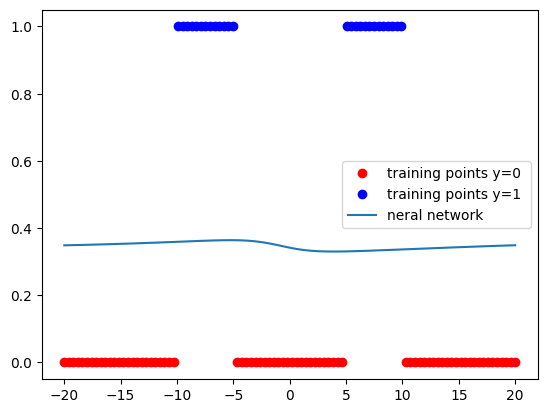

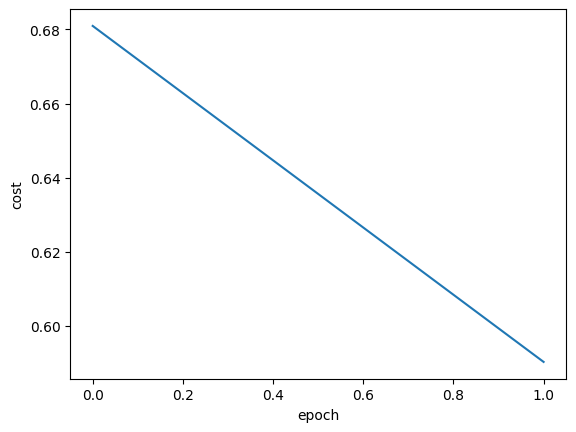

In [10]:
torch.manual_seed(0)
model = Net(1, 9, 1)
learning_rate = 0.1
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
train_loader = DataLoader(dataset=data_set, batch_size=100)
COST = train(data_set, model, criterion, train_loader, optimizer, epochs=2, plot_number=200)

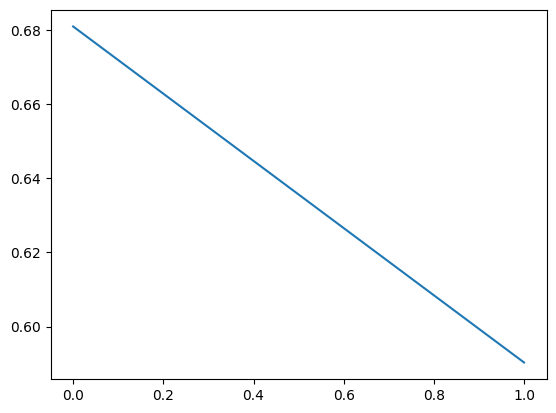

In [11]:
plt.plot(COST)

<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>, <a href="https://www.linkedin.com/in/fanjiang0619/">Fan Jiang</a>, <a href="https://www.linkedin.com/in/yi-leng-yao-84451275/">Yi Leng Yao</a>, <a href="https://www.linkedin.com/in/sacchitchadha/">Sacchit Chadha</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |
-->





## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
